<a href="https://colab.research.google.com/github/thakuranu0314-eng/RSNA-Intracranial-Aneurysm-Detection/blob/main/RSNA_Aneurysm_Detection_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Intracranial Aneurysm Detection Using Deep Learning

## 1. Project Overview

### 1.1 Background
An intracranial aneurysm is an abnormal bulging or dilation of a blood vessel in the brain. Some aneurysms may rupture and cause subarachnoid hemorrhage, a potentially life-threatening condition.

Computed Tomography Angiography (CTA) is a medical imaging technique that uses X-rays and an intravenous contrast agent to visualize blood vessels. CTA can help identify intracranial aneurysms.

Deep learning has the potential to assist in the analysis of medical images by identifying patterns associated with aneurysms.

### 1.2 Project Objective
The initial objective is to explore CTA images and prepare a deep learning workflow for binary classification:

- **Class 0:** Aneurysm absent
- **Class 1:** Aneurysm present

The long-term goal is to develop and evaluate a model that predicts aneurysm presence at the scan level.

### 1.3 Dataset
**Dataset:** RSNA Intracranial Aneurysm Detection (Kaggle)

The dataset includes medical imaging scans, scan-level labels, imaging metadata, and aneurysm localizer annotations for selected positive scans.

The initial analysis focuses on the CTA modality.

### 1.4 Scope of Exploratory Data Analysis
This notebook will cover:

1. Dataset loading and structure
2. Missing-value and label analysis
3. CTA subset selection and class distribution
4. DICOM metadata exploration
5. CTA volume reconstruction and visualization
6. Aneurysm annotation verification
7. Initial negative-scan exploration
8. Key findings, limitations, and next steps

### 1.5 Expected Outcome
The EDA will help us understand dataset characteristics, image geometry, annotation structure, and preprocessing challenges before selecting and training a baseline deep learning model.

**Project stage:** Exploratory Data Analysis (EDA). No model training is performed in this notebook.

## 2. Environment Setup

### 2.1 Install Required Python Libraries

This project uses Google Colab as the computational environment. We will install the libraries needed to access the RSNA dataset, read medical images, and perform exploratory data analysis.

**Libraries:**
- **kaggle:** Access and download competition data from Kaggle.
- **pydicom:** Read DICOM medical imaging files and their metadata.
- **pandas:** Explore and analyze tabular metadata and labels.
- **numpy:** Perform numerical operations and reconstruct image volumes.
- **matplotlib:** Visualize images and dataset distributions.
- **seaborn:** Create statistical plots.

**Expected outcome:** The required packages are available for subsequent analysis.

In [ ]:
%pip -q install kaggle pydicom pandas numpy matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 8.0 MB/s eta 0:00:00


### 2.2 Import Python Libraries

**Purpose:** Import the Python libraries required for dataset exploration, medical image processing, and visualization.

**Method:** Load libraries for tabular data analysis (`pandas`), numerical operations (`numpy`), DICOM processing (`pydicom`), and visualization (`matplotlib` and `seaborn`). The Kaggle API will be used later to access the competition dataset.

**Expected output:** A confirmation that the libraries were imported successfully.

In [ ]:
import os
import numpy as np
import pandas as pd
import pydicom
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

print("All libraries imported successfully.")

All libraries imported successfully.


### 2.3 Check Available Storage

**Purpose:** Determine whether the Google Colab environment has sufficient disk space to download and extract the medical imaging dataset.

**Method:** Use Python's `shutil.disk_usage()` function to measure total, used, and available disk storage.

**Importance:** CTA studies contain hundreds of DICOM images per scan. Downloading a large collection requires substantial storage, and extracted files may occupy more space than compressed archives.

**Expected output:** Total, used, and free storage in gigabytes (GB).

In [ ]:
import shutil

total, used, free = shutil.disk_usage("/content")

gb = 1024 ** 3

print(f"Total storage: {total / gb:.2f} GiB")
print(f"Used storage:  {used / gb:.2f} GiB")
print(f"Free storage:  {free / gb:.2f} GiB")

Total storage: 107.72 GiB
Used storage:  20.51 GiB
Free storage:  87.19 GiB


### 2.4 Configure Kaggle Authentication

**Purpose:** Authenticate Google Colab with Kaggle to access the RSNA Intracranial Aneurysm Detection competition dataset.

**Method:** Upload a personal Kaggle API credential file (`kaggle.json`) and configure the Kaggle API client.

**Security:** The API credential is private and must not be included in the shared notebook, printed in outputs, or uploaded to a public repository.

**Expected output:** Confirmation that Kaggle authentication has been configured successfully.

In [ ]:
from google.colab import files
import os
import json

# Upload credentials
uploaded = files.upload()

if "kaggle.json" not in uploaded:
    raise FileNotFoundError("Please upload kaggle.json")

# Set Kaggle configuration directory
os.makedirs("/root/.kaggle", exist_ok=True)

with open("/root/.kaggle/kaggle.json", "wb") as f:
    f.write(uploaded["kaggle.json"])

os.chmod("/root/.kaggle/kaggle.json", 0o600)

# Read credentials without displaying them
with open("/root/.kaggle/kaggle.json") as f:
    credentials = json.load(f)

# Support legacy Kaggle API credentials
if "username" not in credentials or "key" not in credentials:
    raise ValueError(
        "This file does not contain a Kaggle username and API key."
    )

os.environ["KAGGLE_CONFIG_DIR"] = "/root/.kaggle"
os.environ["KAGGLE_USERNAME"] = credentials["username"]
os.environ["KAGGLE_KEY"] = credentials["key"]

from kaggle.api.kaggle_api_extended import KaggleApi

api = KaggleApi()
api.authenticate()

print("Kaggle authentication successful!")

Saving kaggle.json to kaggle.json
Kaggle authentication successful!


## 3. Dataset Access and Download Planning

### 3.1 Inspect Competition Files

**Purpose:** Verify access to the RSNA Intracranial Aneurysm Detection dataset and inspect its downloadable files before downloading the medical images.

**Method:** Use the authenticated Kaggle API to retrieve the competition file listing and examine filenames and reported sizes.

**Importance:** Medical imaging datasets can contain thousands of DICOM files. Checking their organization and size helps us choose a reliable download strategy and avoid exceeding Colab storage limits.

**Expected output:** A list of competition files and their reported sizes. No image files will be downloaded in this step.

In [ ]:
import inspect

competition = "rsna-intracranial-aneurysm-detection"

print("Kaggle API method signature:")
print(inspect.signature(api.competition_list_files))

print("\nMethod documentation:")
print(inspect.getdoc(api.competition_list_files))

Kaggle API method signature:
(competition: str, page_token: Optional[str] = None, page_size: int = 20) -> kagglesdk.competitions.types.competition_api_service.ApiListDataFilesResponse

Method documentation:
Lists files for a competition.

Args:
    competition (str): The name of the competition.
    page_token (Optional[str]): The page token for pagination.
    page_size (int): The number of items per page.

Returns:
    ApiListDataFilesResponse:


In [ ]:
competition = "rsna-intracranial-aneurysm-detection"

# Retrieve the first 20 competition files
file_listing = api.competition_list_files(
    competition=competition,
    page_size=20
)

print("Files returned:", len(file_listing.files))
print("\nSample competition files:\n")

for item in file_listing.files:
    print(
        "Name:", item.name,
        "| Size:", getattr(item, "total_bytes", "Not reported")
    )

print("\nMore pages available:",
      bool(getattr(file_listing, "next_page_token", None)))

Files returned: 20

Sample competition files:

Name: kaggle_evaluation/__init__.py | Size: 708
Name: kaggle_evaluation/core/__init__.py | Size: 83
Name: kaggle_evaluation/core/base_gateway.py | Size: 22880
Name: kaggle_evaluation/core/generated/__init__.py | Size: 83
Name: kaggle_evaluation/core/generated/kaggle_evaluation_pb2.py | Size: 4074
Name: kaggle_evaluation/core/generated/kaggle_evaluation_pb2_grpc.py | Size: 2662
Name: kaggle_evaluation/core/kaggle_evaluation.proto | Size: 1789
Name: kaggle_evaluation/core/relay.py | Size: 18118
Name: kaggle_evaluation/core/templates.py | Size: 5105
Name: kaggle_evaluation/rsna_gateway.py | Size: 5461
Name: kaggle_evaluation/rsna_inference_server.py | Size: 381
Name: kaggle_evaluation/series/1.2.826.0.1.3680043.8.498.10028406715369553772267826812576760572/1.2.826.0.1.3680043.8.498.10086425055396889038257927884122962676.dcm | Size: 132024
Name: kaggle_evaluation/series/1.2.826.0.1.3680043.8.498.10028406715369553772267826812576760572/1.2.826.0.

### 3.2 Check Dataset Download Requirements

**Purpose:** Examine the available Kaggle competition download methods before retrieving the full medical imaging dataset.

**Method:** Inspect the Kaggle API's download functions and their supported parameters without initiating a download.

**Importance:** The dataset contains many DICOM images. Selecting the correct download method helps avoid unnecessary API requests, incomplete transfers, and storage problems.

**Expected output:** Download method signatures and documentation to guide our download strategy.

In [ ]:
import inspect

print("Single-file download:")
print(inspect.signature(api.competition_download_file))

print("\nComplete competition download:")
print(inspect.signature(api.competition_download_files))

print("\nComplete competition download documentation:")
print(inspect.getdoc(api.competition_download_files))

Single-file download:
(competition: str, file_name: str, path: Optional[str] = None, force: bool = False, quiet: bool = False) -> None

Complete competition download:
(competition: str, path: Optional[str] = None, force: bool = False, quiet: bool = True) -> None

Complete competition download documentation:
Downloads all competition files.

Args:
    competition (str): The name of the competition.
    path (Optional[str]): A path to download the file to.
    force (bool): Force the download if the file already exists (default False).
    quiet (bool): Suppress verbose output (default is True).

Returns:
    None:


### 3.3 Estimate Download Size

**Purpose:** Determine whether downloading the entire competition dataset is practical within the available Colab storage.

**Method:** Inspect the size of the complete dataset using the Kaggle API's competition metadata, without downloading the images.

**Importance:** The competition includes multiple imaging modalities. Our initial analysis focuses on CTA, so downloading all modalities may consume unnecessary storage.

**Expected output:** Available competition metadata and any reported dataset size information.

In [ ]:
# Retrieve competition metadata
response = api.competitions_list(
    search="rsna-intracranial-aneurysm-detection"
)

# Extract competitions from the response
competitions = response.competitions

print("Competitions found:", len(competitions))

for comp in competitions:
    print("\nCompetition:", getattr(comp, "ref", "N/A"))
    print("Title:", getattr(comp, "title", "N/A"))
    print("Total bytes:", getattr(comp, "total_bytes", "Not available"))
    print("Dataset size:", getattr(comp, "size", "Not available"))

Competitions found: 1

Competition: https://www.kaggle.com/competitions/rsna-intracranial-aneurysm-detection
Title: RSNA Intracranial Aneurysm Detection
Total bytes: Not available
Dataset size: Not available


### 3.4 Configure Local Project Storage

**Purpose:** Organize the RSNA Intracranial Aneurysm Detection dataset and analysis outputs in Google Colab.

**Method:** Create a dedicated project directory with separate folders for:
- `data/` — Dataset files, including CSV metadata.
- `data/images/` — DICOM medical images.
- `outputs/` — Generated figures and analysis results.

**Importance:** A structured directory makes it easier to locate and manage files during exploratory data analysis.

**Expected Output:** Confirmation that the project folders have been created successfully.

**Note:** Files stored in Colab's `/content` directory are temporary and may be deleted when the runtime resets.

In [ ]:
from pathlib import Path
import shutil

# Create project folders in Colab
project_dir = Path("/content/RSNA_Aneurysm_Project")
data_dir = project_dir / "data"
images_dir = data_dir / "images"
output_dir = project_dir / "outputs"

for folder in [data_dir, images_dir, output_dir]:
    folder.mkdir(parents=True, exist_ok=True)

# Check available storage
total, used, free = shutil.disk_usage("/content")

print("Project directory:", project_dir)
print("Images directory:", images_dir)
print(f"Available storage: {free / (1024**3):.2f} GiB")
print("Project folders created successfully!")

Project directory: /content/RSNA_Aneurysm_Project
Images directory: /content/RSNA_Aneurysm_Project/data/images
Available storage: 87.18 GiB
Project folders created successfully!


### 3.5 Download Training Metadata

**Purpose:** Download the metadata required to explore the RSNA Intracranial Aneurysm Detection dataset.

**Dataset:** RSNA Intracranial Aneurysm Detection (Kaggle).

**Files:**
- `train.csv` — Contains training scan information, imaging modalities, and aneurysm labels.
- `train_localizers.csv` — Contains aneurysm localization annotations for selected positive scans.

**Method:** Use the authenticated Kaggle API to download the two CSV files into the project's `data/` directory.

**Importance:** These metadata files allow us to identify CTA scans, examine class distributions, and match aneurysm annotations to DICOM images.

**Expected Output:** Confirmation that both CSV files have been downloaded successfully.

**Note:** DICOM images will be downloaded separately after selecting the CTA scans.

In [ ]:
from pathlib import Path

competition = "rsna-intracranial-aneurysm-detection"

metadata_files = [
    "train.csv",
    "train_localizers.csv"
]

for filename in metadata_files:
    print(f"\nDownloading {filename}...")

    api.competition_download_file(
        competition=competition,
        file_name=filename,
        path=str(data_dir),
        force=False,
        quiet=False
    )

print("\nDownloaded files:")

for filename in metadata_files:
    matches = list(data_dir.glob(filename + "*"))

    if matches:
        for file in matches:
            print(f"{file.name}: {file.stat().st_size / 1024:.2f} KB")
    else:
        print(f"{filename}: Not found")

100%|██████████| 461k/461k [00:00<00:00, 496kB/s]


100%|██████████| 478k/478k [00:00<00:00, 504kB/s]



Downloaded files:
train.csv: 461.41 KB
train_localizers.csv: 478.22 KB


## 4. Exploratory Data Analysis (EDA)

### 4.1 Load and Inspect Training Metadata

**Purpose:** Load the RSNA training metadata and aneurysm localization annotations to understand the structure of the dataset.

**Method:**
- Read `train.csv` and `train_localizers.csv` using Pandas.
- Examine the number of rows and columns in each dataset.
- Display the first five records.
- Identify the available variables and annotation information.

**Scientific Relevance:**
- Each row in `train.csv` represents an imaging series with associated metadata and aneurysm labels.
- `train_localizers.csv` provides additional information about the approximate locations of annotated aneurysms.
- Understanding the metadata structure is essential before selecting CTA scans and processing DICOM images.

**Expected Output:**
- Dimensions of both datasets.
- Column names.
- First five records from each dataset.

In [ ]:
# Load training metadata and aneurysm annotations
train_df = pd.read_csv(data_dir / "train.csv")
annotations_df = pd.read_csv(data_dir / "train_localizers.csv")

# Display dataset dimensions
print("Training metadata shape:", train_df.shape)
print("Localizer annotations shape:", annotations_df.shape)

# Display column names
print("\nTraining metadata columns:")
print(train_df.columns.tolist())

print("\nLocalizer annotation columns:")
print(annotations_df.columns.tolist())

# Preview both datasets
print("\nTraining metadata preview:")
display(train_df.head())

print("\nLocalizer annotations preview:")
display(annotations_df.head())

Training metadata shape: (4348, 18)
Localizer annotations shape: (2254, 4)

Training metadata columns:
['SeriesInstanceUID', 'PatientAge', 'PatientSex', 'Modality', 'Left Infraclinoid Internal Carotid Artery', 'Right Infraclinoid Internal Carotid Artery', 'Left Supraclinoid Internal Carotid Artery', 'Right Supraclinoid Internal Carotid Artery', 'Left Middle Cerebral Artery', 'Right Middle Cerebral Artery', 'Anterior Communicating Artery', 'Left Anterior Cerebral Artery', 'Right Anterior Cerebral Artery', 'Left Posterior Communicating Artery', 'Right Posterior Communicating Artery', 'Basilar Tip', 'Other Posterior Circulation', 'Aneurysm Present']

Localizer annotation columns:
['SeriesInstanceUID', 'SOPInstanceUID', 'coordinates', 'location']

Training metadata preview:


,SeriesInstanceUID,PatientAge,PatientSex,Modality,Left Infraclinoid Internal Carotid Artery,Right Infraclinoid Internal Carotid Artery,Left Supraclinoid Internal Carotid Artery,Right Supraclinoid Internal Carotid Artery,Left Middle Cerebral Artery,Right Middle Cerebral Artery,Anterior Communicating Artery,Left Anterior Cerebral Artery,Right Anterior Cerebral Artery,Left Posterior Communicating Artery,Right Posterior Communicating Artery,Basilar Tip,Other Posterior Circulation,Aneurysm Present
0,1.2.826.0.1.3680043.8.498.10004044428023505108...,64,Female,MRA,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,1.2.826.0.1.3680043.8.498.10004684224894397679...,76,Female,MRA,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,1.2.826.0.1.3680043.8.498.10005158603912009425...,58,Male,CTA,0,0,0,0,0,0,0,0,0,0,0,0,1,1
3,1.2.826.0.1.3680043.8.498.10009383108068795488...,71,Male,MRA,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,1.2.826.0.1.3680043.8.498.10012790035410518400...,48,Female,MRA,0,0,0,0,0,0,0,0,0,0,0,0,0,0



Localizer annotations preview:


,SeriesInstanceUID,SOPInstanceUID,coordinates,location
0,1.2.826.0.1.3680043.8.498.10005158603912009425...,1.2.826.0.1.3680043.8.498.10775329348174902199...,"{'x': 258.3621186176837, 'y': 261.359900373599}",Other Posterior Circulation
1,1.2.826.0.1.3680043.8.498.10022796280698534221...,1.2.826.0.1.3680043.8.498.53868409774237283281...,"{'x': 194.87253141831238, 'y': 178.32675044883...",Right Middle Cerebral Artery
2,1.2.826.0.1.3680043.8.498.10023411164590664678...,1.2.826.0.1.3680043.8.498.24186535344744886473...,"{'x': 189.23979878597123, 'y': 209.19184886465...",Right Middle Cerebral Artery
3,1.2.826.0.1.3680043.8.498.10030095840917973694...,1.2.826.0.1.3680043.8.498.75217084841854214544...,"{'x': 208.2805049088359, 'y': 229.78962131837307}",Right Infraclinoid Internal Carotid Artery
4,1.2.826.0.1.3680043.8.498.10034081836061566510...,1.2.826.0.1.3680043.8.498.71237104731452368587...,"{'x': 249.86745590416498, 'y': 220.623044646393}",Anterior Communicating Artery


### 4.1.1 Results and Interpretation

The training metadata contains **4,348 imaging series and 18 columns**, while the aneurysm localizer dataset contains **2,254 annotation records and 4 columns**.

**Training metadata (`train.csv`):**
- `SeriesInstanceUID`: Unique identifier for an imaging series.
- `PatientAge` and `PatientSex`: Patient demographic information.
- `Modality`: Medical imaging technique used for the scan.
- Anatomical location columns: Binary labels indicating aneurysm involvement at specific vascular locations.
- `Aneurysm Present`: Main binary classification target (0 = absent, 1 = present).

**Localization annotations (`train_localizers.csv`):**
- `SeriesInstanceUID`: Identifies the imaging series.
- `SOPInstanceUID`: Identifies the DICOM image associated with an annotation.
- `coordinates`: Approximate aneurysm location within that image.
- `location`: Anatomical category of the aneurysm.

**Key Finding:** The dataset provides both scan-level classification labels and additional localization information. For the initial project, we will focus on predicting `Aneurysm Present` rather than aneurysm location.

### 4.2 Data Quality Assessment

**Purpose:** Identify missing values and duplicate imaging series in the training metadata.

**Method:**
- Count missing values in each column.
- Check for duplicate `SeriesInstanceUID` values.
- Examine the data types of the variables.

**Importance:** Missing or duplicated records may affect data analysis and model development. Checking data quality early helps identify potential preprocessing requirements.

**Expected Output:** Missing-value counts, duplicate-series count, and column data types.

In [ ]:
print("Missing values:")
display(train_df.isnull().sum().to_frame("Missing Count"))

print("\nDuplicate SeriesInstanceUID:",
      train_df["SeriesInstanceUID"].duplicated().sum())

print("\nColumn data types:")
display(train_df.dtypes.to_frame("Data Type"))

Missing values:


,Missing Count
SeriesInstanceUID,0
PatientAge,0
PatientSex,0
Modality,0
Left Infraclinoid Internal Carotid Artery,0
Right Infraclinoid Internal Carotid Artery,0
Left Supraclinoid Internal Carotid Artery,0
Right Supraclinoid Internal Carotid Artery,0
Left Middle Cerebral Artery,0
Right Middle Cerebral Artery,0



Duplicate SeriesInstanceUID: 0

Column data types:


,Data Type
SeriesInstanceUID,object
PatientAge,int64
PatientSex,object
Modality,object
Left Infraclinoid Internal Carotid Artery,int64
Right Infraclinoid Internal Carotid Artery,int64
Left Supraclinoid Internal Carotid Artery,int64
Right Supraclinoid Internal Carotid Artery,int64
Left Middle Cerebral Artery,int64
Right Middle Cerebral Artery,int64


### 4.2.1 Results and Interpretation

**Duplicate records:**
- No duplicate `SeriesInstanceUID` values were identified.
- Each row has a unique imaging series identifier.

**Missing values:**
- The displayed aneurysm-label columns contain no missing values.
- Missing-value counts for all columns should be verified before concluding that the entire dataset is complete.

**Data types:**
- Series identifiers, patient sex, and imaging modality are stored as text (`object`).
- Patient age and aneurysm labels are stored as integers (`int64`).

**Key Finding:** The dataset has unique imaging series identifiers and appropriately structured classification labels. Further analysis will focus on imaging modality distribution and aneurysm prevalence.

### 4.3 Imaging Modality Distribution

**Purpose:** Examine the distribution of medical imaging modalities in the training dataset.

**Scientific Background:**
- **CTA (Computed Tomography Angiography):** Uses X-rays and an intravenous contrast agent to visualize blood vessels.
- **MRA (Magnetic Resonance Angiography):** Uses magnetic resonance imaging techniques to visualize blood vessels.
- **MRI (Magnetic Resonance Imaging):** Produces images using magnetic fields and radiofrequency signals. Different MRI sequences provide different tissue contrasts.

**Method:**
- Count imaging series by modality.
- Calculate their percentage distribution.
- Visualize the results using a bar chart.

**Importance:** Different imaging modalities have distinct image characteristics and preprocessing requirements. Understanding their distribution helps justify selecting CTA for the initial deep learning workflow.

**Expected Output:** A frequency table and bar chart showing the number of imaging series for each modality.

,Number of Scans,Percentage (%)
Modality,,
CTA,1808,41.58
MRA,1252,28.79
MRI T2,983,22.61
MRI T1post,305,7.01


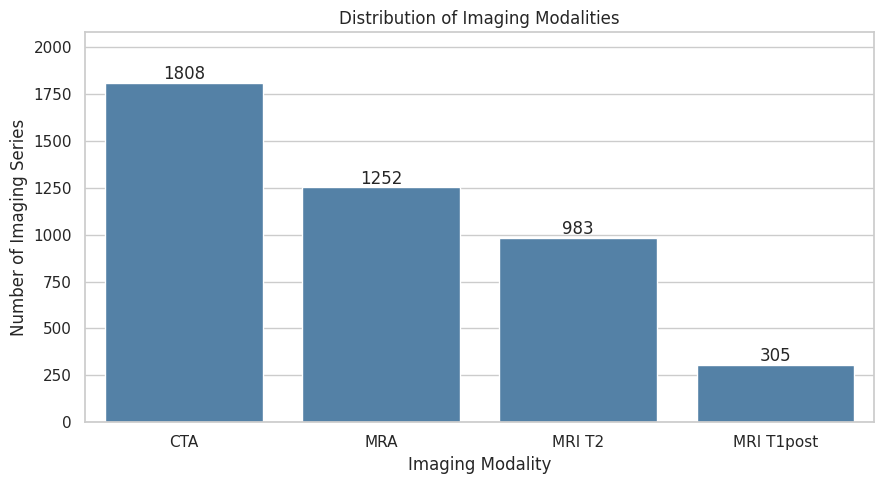

In [ ]:
# Count imaging series by modality
modality_counts = train_df["Modality"].value_counts()

modality_summary = pd.DataFrame({
    "Number of Scans": modality_counts,
    "Percentage (%)": (
        modality_counts / len(train_df) * 100
    ).round(2)
})

display(modality_summary)

# Visualize modality distribution
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=modality_counts.index,
    y=modality_counts.values,
    color="steelblue"
)

for i, count in enumerate(modality_counts.values):
    ax.text(i, count + 20, str(count), ha="center")

plt.title("Distribution of Imaging Modalities")
plt.xlabel("Imaging Modality")
plt.ylabel("Number of Imaging Series")
plt.ylim(0, modality_counts.max() * 1.15)
plt.tight_layout()
plt.show()

### 4.3.1 Results and Interpretation

The training dataset contains 4,348 imaging series distributed across four modalities:

| Imaging Modality | Number of Series | Percentage |
|---|---:|---:|
| CTA | 1,808 | 41.58% |
| MRA | 1,252 | 28.79% |
| MRI T2 | 983 | 22.61% |
| MRI T1post | 305 | 7.01% |

**Key Findings:**
- CTA is the most common imaging modality, accounting for 41.58% of the dataset.
- MRA is the second-largest category, representing 28.79%.
- MRI T2 and MRI T1post account for the remaining imaging series.
- The distribution is not uniform across imaging modalities.

**Decision:** CTA has been selected for the initial binary classification project because it provides the largest single-modality subset and allows us to develop a more consistent imaging pipeline.

**Next Step:** Investigate aneurysm prevalence and class balance before selecting the CTA subset.

### 4.4 Aneurysm Label Distribution

**Purpose:** Examine the distribution of positive and negative aneurysm labels across the complete training dataset.

**Scientific Background:**

An intracranial aneurysm is an abnormal dilation of an intracranial blood vessel.

The target variable `Aneurysm Present` contains two classes:

- **0 (Negative):** No aneurysm labeled as present.
- **1 (Positive):** At least one aneurysm labeled as present.

**Method:**
1. Count the number of positive and negative imaging series.
2. Calculate the percentage of each class.
3. Visualize the class distribution using a bar chart.

**Importance:** Class imbalance can affect machine learning performance. Understanding the distribution helps us select appropriate evaluation metrics and training strategies.

**Expected Output:** A table and bar chart showing positive and negative aneurysm labels.

,Number of Scans,Percentage (%)
Negative (0),2485,57.15
Positive (1),1863,42.85


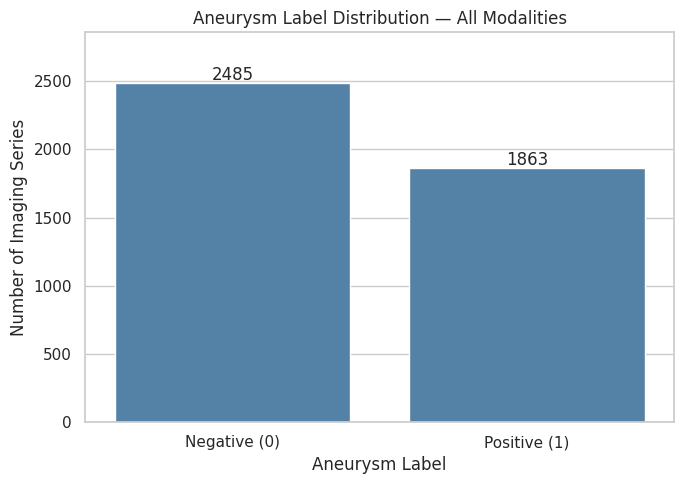

In [ ]:
# Calculate aneurysm label distribution
label_counts = train_df["Aneurysm Present"].value_counts().sort_index()

label_summary = pd.DataFrame({
    "Number of Scans": label_counts,
    "Percentage (%)": (
        label_counts / len(train_df) * 100
    ).round(2)
})

label_summary.index = ["Negative (0)", "Positive (1)"]

display(label_summary)

# Visualize class distribution
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=["Negative (0)", "Positive (1)"],
    y=label_counts.values,
    color="steelblue"
)

for i, count in enumerate(label_counts.values):
    ax.text(i, count + 20, str(count), ha="center")

plt.title("Aneurysm Label Distribution — All Modalities")
plt.xlabel("Aneurysm Label")
plt.ylabel("Number of Imaging Series")
plt.ylim(0, label_counts.max() * 1.15)
plt.tight_layout()
plt.show()

### 4.4.1 Results and Interpretation

The training dataset contains 4,348 imaging series.

| Aneurysm Label | Number of Series | Percentage |
|---|---:|---:|
| Negative (0) | 2,485 | 57.15% |
| Positive (1) | 1,863 | 42.85% |

**Key Findings:**
- Negative imaging series represent 57.15% of the dataset.
- Positive imaging series represent 42.85%.
- The dataset shows moderate class imbalance, with approximately 1.33 negative series for every positive series.
- Accuracy alone may not be sufficient for evaluating a medical image classification model.

**Decision:** Class balance will be considered when selecting training strategies and evaluation metrics.

**Next Step:** Select the CTA subset and examine its class distribution separately.

### 4.5 CTA Subset Selection and Class Distribution

**Purpose:** Extract CTA imaging series from the complete training dataset and examine the distribution of aneurysm labels within this subset.

**Scientific Background:**

Computed Tomography Angiography (CTA) uses X-ray-based CT imaging and intravenous contrast material to visualize blood vessels.

CTA is useful for studying intracranial aneurysms because it provides detailed images of cerebral vascular anatomy.

**Method:**
1. Filter the training metadata to include only CTA imaging series.
2. Count positive and negative aneurysm labels.
3. Calculate the percentage distribution of both classes.
4. Visualize the results using a bar chart.

**Importance:** The class distribution within CTA may differ from the overall dataset. Understanding this distribution is essential before preparing the data for model development.

**Expected Output:** CTA subset dimensions, class distribution table, and visualization.

Total CTA scans: 1808


,Number of Scans,Percentage (%)
Negative (0),835,46.18
Positive (1),973,53.82


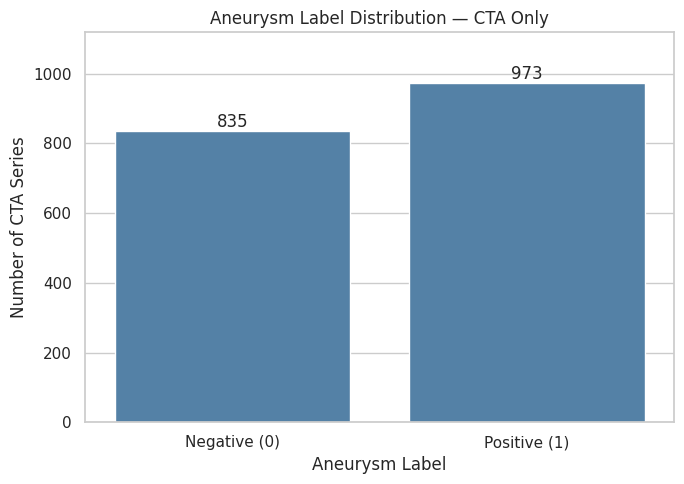

In [ ]:
# Select CTA imaging series
cta_df = train_df[train_df["Modality"] == "CTA"].copy()

print("Total CTA scans:", len(cta_df))

# Calculate CTA label distribution
cta_counts = (
    cta_df["Aneurysm Present"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

cta_summary = pd.DataFrame({
    "Number of Scans": cta_counts,
    "Percentage (%)": (
        cta_counts / len(cta_df) * 100
    ).round(2)
})

cta_summary.index = ["Negative (0)", "Positive (1)"]

display(cta_summary)

# Plot CTA class distribution
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=["Negative (0)", "Positive (1)"],
    y=cta_counts.values,
    color="steelblue"
)

for i, count in enumerate(cta_counts.values):
    ax.text(i, count + 12, str(count), ha="center")

plt.title("Aneurysm Label Distribution — CTA Only")
plt.xlabel("Aneurysm Label")
plt.ylabel("Number of CTA Series")
plt.ylim(0, cta_counts.max() * 1.15)

plt.tight_layout()
plt.show()

### 4.5.1 Results and Interpretation

The CTA subset contains **1,808 imaging series**, representing 41.58% of the complete training dataset.

| Aneurysm Label | Number of Series | Percentage |
|---|---:|---:|
| Negative (0) | 835 | 46.18% |
| Positive (1) | 973 | 53.82% |

**Key Findings:**
- The CTA subset contains slightly more positive than negative series.
- Positive CTA series represent 53.82% of the subset.
- Negative CTA series represent 46.18%.
- The class distribution is relatively balanced, with a positive-to-negative ratio of approximately 1.17:1.
- The CTA class distribution differs from the overall training dataset.

**Conclusion:** The CTA subset is suitable for initial exploratory analysis and baseline model development. We will evaluate class balance again after creating training and validation splits.

**Next Step:** Examine the distribution of aneurysm locations within CTA scans.

### 4.6 Anatomical Distribution of Aneurysms in CTA

**Purpose:** Explore the anatomical locations of aneurysms in CTA imaging series.

**Scientific Background:**

Intracranial aneurysms can occur in different cerebral arteries, including:
- Internal carotid artery (ICA)
- Middle cerebral artery (MCA)
- Anterior communicating artery (ACoA)
- Posterior communicating artery (PCoA)
- Basilar artery and other posterior circulation vessels

**Method:**
1. Identify the anatomical location columns in the training metadata.
2. Count positive labels for each location within the CTA subset.
3. Visualize the distribution using a horizontal bar chart.

**Importance:** Understanding anatomical distribution helps identify which vascular regions are represented in the dataset and whether some aneurysm locations are less common.

**Expected Output:** A table and bar chart showing the frequency of aneurysm location labels.

**Note:** A single imaging series may have more than one positive location label. Therefore, location counts may exceed the number of positive CTA series.

,Positive Location Labels
Anterior Communicating Artery,232
Right Middle Cerebral Artery,161
Left Supraclinoid Internal Carotid Artery,145
Left Middle Cerebral Artery,130
Right Supraclinoid Internal Carotid Artery,104
Right Posterior Communicating Artery,73
Basilar Tip,65
Other Posterior Circulation,65
Left Posterior Communicating Artery,62
Right Infraclinoid Internal Carotid Artery,46


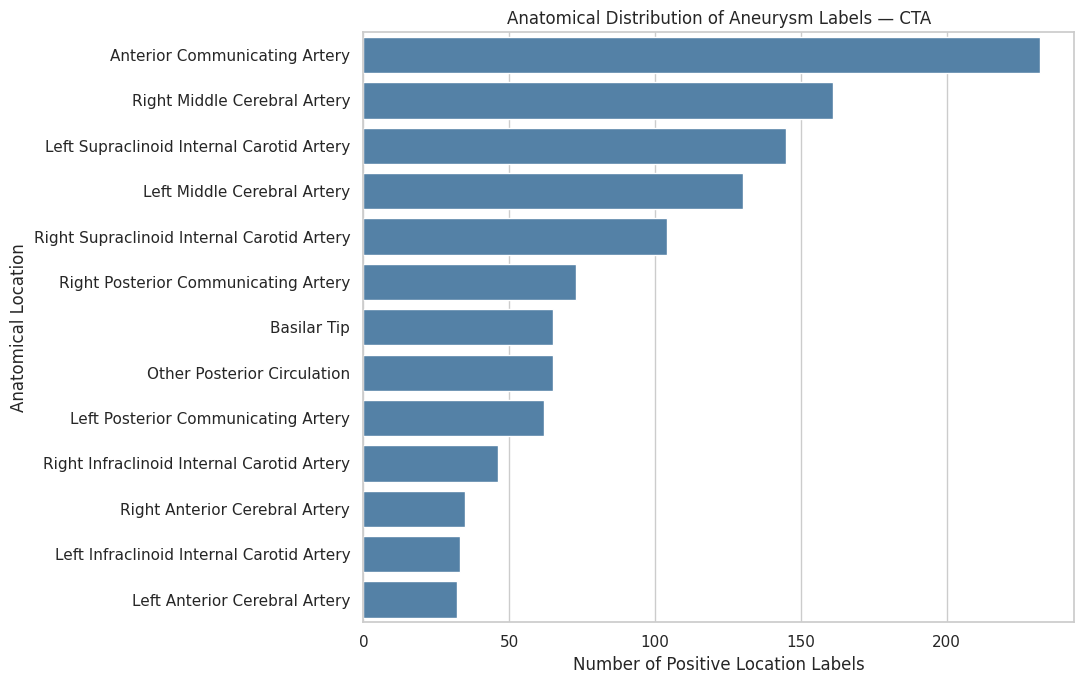

In [ ]:
# Identify the anatomical location columns
location_cols = train_df.columns[4:-1].tolist()

# Count positive labels at each location within CTA
location_counts = (
    cta_df[location_cols]
    .sum()
    .sort_values(ascending=False)
)

display(
    location_counts.to_frame("Positive Location Labels")
)

# Visualize anatomical distribution
plt.figure(figsize=(11, 7))

sns.barplot(
    x=location_counts.values,
    y=location_counts.index,
    color="steelblue"
)

plt.title("Anatomical Distribution of Aneurysm Labels — CTA")
plt.xlabel("Number of Positive Location Labels")
plt.ylabel("Anatomical Location")
plt.tight_layout()
plt.show()

### 4.7 Patient Demographic Analysis

**Purpose:** Examine patient age and sex distributions within the CTA subset and compare them between positive and negative aneurysm labels.

**Scientific Background:**
Age and sex are relevant demographic variables in intracranial aneurysm research. However, observed associations in this competition dataset may reflect selection or sampling effects and should not be interpreted as population-level risk estimates.

**Method:**
1. Calculate descriptive statistics for patient age.
2. Examine patient sex distribution.
3. Compare age distributions between positive and negative CTA series.
4. Visualize the results using histograms and boxplots.

**Importance:** Demographic exploration helps identify potential differences between classification groups and possible confounding variables.

**Expected Output:** Age summary statistics, sex distribution, and age comparison plots.

CTA Patient Age Summary:


,Age
count,1808.000000
mean,59.162058
std,15.692562
min,18.000000
25%,49.000000
50%,60.000000
75%,70.000000
max,89.000000



CTA Patient Sex Distribution:


,Count
PatientSex,
Female,1180
Male,628


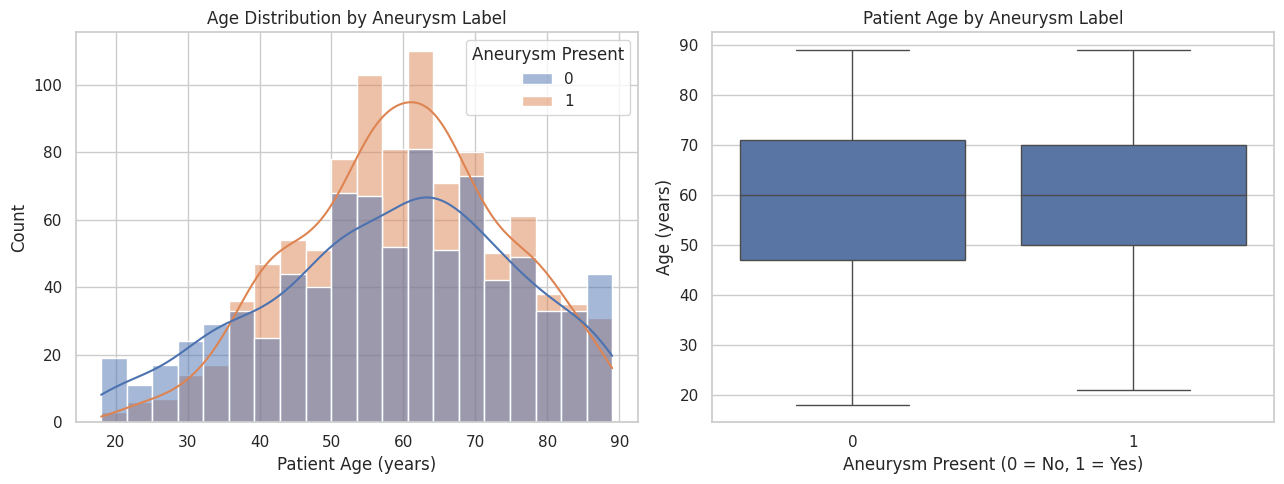

In [ ]:
# Patient age summary
print("CTA Patient Age Summary:")
display(cta_df["PatientAge"].describe().to_frame("Age"))

# Patient sex distribution
print("\nCTA Patient Sex Distribution:")
display(cta_df["PatientSex"].value_counts().to_frame("Count"))

# Age distribution by aneurysm label
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    data=cta_df,
    x="PatientAge",
    hue="Aneurysm Present",
    bins=20,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Age Distribution by Aneurysm Label")
axes[0].set_xlabel("Patient Age (years)")

sns.boxplot(
    data=cta_df,
    x="Aneurysm Present",
    y="PatientAge",
    ax=axes[1]
)

axes[1].set_title("Patient Age by Aneurysm Label")
axes[1].set_xlabel("Aneurysm Present (0 = No, 1 = Yes)")
axes[1].set_ylabel("Age (years)")

plt.tight_layout()
plt.show()

### 4.7.1 Results and Interpretation

Demographic characteristics were examined across 1,808 CTA imaging series.

**Age Distribution:**
- Mean age: 59.16 years
- Median age: 60 years
- Standard deviation: 15.69 years
- Age range: 18–89 years
- Most imaging series involve patients in middle or older adulthood.
- Positive and negative groups have similar median ages, although their distributions differ slightly.

**Sex Distribution:**
- Female: 1,180 (65.27%)
- Male: 628 (34.73%)

**Key Findings:**
- Female patients account for a larger proportion of the CTA imaging series.
- Both aneurysm-positive and aneurysm-negative groups cover a broad age range.
- Demographic patterns in this dataset should not be interpreted as population-level aneurysm risk estimates.

**Conclusion:**
Demographic analysis provides useful context for understanding the dataset and potential sources of bias. The initial model will focus on CTA images, while demographic variables may be considered in later evaluation.

## 5. CTA Image Acquisition and Visualization

### Objective

The next stage of this project is to examine complete CT angiography (CTA) imaging series.

### Planned Workflow

1. Select representative aneurysm-positive and aneurysm-negative CTA series.
2. Obtain the complete DICOM images for each selected series.
3. Verify image completeness and DICOM metadata.
4. Reconstruct the image volumes in the correct anatomical order.
5. Visualize axial CTA slices.
6. Identify annotated aneurysm locations and examine their correspondence with the images.

### Data Management Considerations

The complete RSNA competition download is approximately 200.10 GiB, exceeding the 87.18 GiB available in the current Google Colab environment.

Therefore, selective acquisition of complete CTA imaging series is necessary.

### Current Status

Tabular exploratory data analysis has been completed. Image acquisition and visualization remain pending.